# Självstudieövningar – Vecka 7

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men dokumentationerna är din bästa vän när du lär dig.
- Python: https://docs.python.org/3.13/
- Matplotlib: https://matplotlib.org/stable/
- Pandas: https://pandas.pydata.org/
- NumPy: https://numpy.org/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

n = 800
cities = np.array(["Göteborg", "Malmö", "Stockholm", "Uppsala"])
genders = np.array(["F", "M"])
groups = np.array(["A", "B"])

city = rng.choice(cities, size=n, p=[0.28, 0.22, 0.40, 0.10])
gender = rng.choice(genders, size=n)
age = rng.integers(18, 65, size=n)
group = rng.choice(groups, size=n)

base = rng.normal(60, 12, size=n)
city_shift = {"Göteborg": 2, "Malmö": -1, "Stockholm": 1, "Uppsala": 0}
gender_shift = {"F": 1.5, "M": 0}
score = base + np.vectorize(city_shift.get)(city) + np.vectorize(gender_shift.get)(gender)
score = score + np.where(group == "B", 2.0, 0.0)
score = np.clip(score, 10, 100)

p_buy = 1 / (1 + np.exp(-(score - 55) / 10))
purchase = rng.binomial(1, p_buy)
revenue = np.where(purchase == 1, rng.lognormal(mean=3.2, sigma=0.5, size=n), 0.0)

df = pd.DataFrame({
    "city": city,
    "gender": gender,
    "age": age,
    "group": group,
    "score": np.round(score, 1),
    "purchase": purchase,
    "revenue": np.round(revenue, 2)
})

mask = rng.random(size=df.shape) < 0.01
for (row, column), is_missing in np.ndenumerate(mask):
    if is_missing:
        df.iat[row, column] = np.nan

df.to_csv("customer_activity.csv", index=False)
print("Skapade customer_activity.csv med", len(df), "rader.")

Skapade customer_activity.csv med 800 rader.


### Om datasetet (`customer_activity.csv`)

Det här är samma syntetiska dataset från den fiktiva digitala tjänsten som användes under vecka 5 och 6. Grupp B har en liten positiv effekt på `score`, och sannolikheten för ett köp ökar med högre `score`.

| Kolumn | Typ | Beskrivning |
|---|---|---|
| `city` | kategori | Kundens stad |
| `gender` | kategori | Kön (F/M) |
| `age` | heltal | Ålder |
| `group` | kategori | Grupp A eller B |
| `score` | decimaltal | Aktivitet eller engagemang, 10–100 |
| `purchase` | 0/1 | Om kunden genomförde ett köp |
| `revenue` | decimaltal | Intäkt, 0 om inget köp genomfördes |

Eftersom datasetet är syntetiskt ska det användas för att träna analysmetoder. Resultaten beskriver inte verkliga kunder.

### Snabb kontroll

- Läs in `customer_activity.csv` i en DataFrame som heter `df`.
- Kontrollera datatyper och antal saknade värden.
- Kontrollera att `group` bara innehåller A och B samt att `purchase` bara innehåller 0 och 1, bortsett från saknade värden.

In [2]:
df = pd.read_csv('customer_activity.csv')
df = df.dropna()
df.sample(5)
df.info()
df.isna().sum()
df['group'].value_counts(dropna=False)
df['purchase'].value_counts(dropna=False)
valid_groups = df['group'].dropna().isin(['A', 'B']).all()
valid_purchases = df['purchase'].dropna().isin([0, 1]).all()
print(f'Valid groups: {valid_groups}')
print(f'Valid purchases: {valid_purchases}')
df.describe(include='all').T

<class 'pandas.DataFrame'>
Index: 742 entries, 0 to 799
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   city      742 non-null    str    
 1   gender    742 non-null    str    
 2   age       742 non-null    float64
 3   group     742 non-null    str    
 4   score     742 non-null    float64
 5   purchase  742 non-null    float64
 6   revenue   742 non-null    float64
dtypes: float64(4), str(3)
memory usage: 46.4 KB
Valid groups: True
Valid purchases: True


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city,742,4,Stockholm,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,742,2,M,402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,742.0,NaN,NaN,NaN,40.715633,13.242419,18.0,29.0,41.0,52.0,64.0
group,742,2,A,372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,742.0,NaN,NaN,NaN,61.643396,11.804505,23.5,53.7,61.3,69.875,97.8
purchase,742.0,NaN,NaN,NaN,0.645553,0.478668,0.0,0.0,1.0,1.0,1.0
revenue,742.0,NaN,NaN,NaN,17.731456,17.355634,0.0,0.0,16.365,29.0475,93.55


## Block A – A/B-test för andelar

### Uppgift 1 – Test av andelar

Undersök om andelen kunder som genomfört ett köp skiljer sig mellan grupp A och grupp B.

- Ta bort rader där `group` eller `purchase` saknas.
- Kontrollera att `purchase` bara innehåller 0 och 1.
- Beräkna antal observationer, antal köp och köpandel i respektive grupp.
- Formulera en nollhypotes och en tvåsidig mothypotes.
- Kontrollera att det förväntade antalet köp och icke-köp är tillräckligt stort i båda grupperna.
- Genomför ett tvåsidigt z-test för två oberoende andelar.
- Rapportera z-statistika, p-värde och slutsats vid signifikansnivån 5 procent.

**Tips:** `statsmodels.stats.proportion.proportions_ztest()` kan användas.

In [3]:
counts = df.groupby('group')['purchase'].agg(
    purchases='sum',
    observations='count'
)
counts['purchase_rate'] = counts['purchases'] / counts['observations'] * 100
counts

,purchases,observations,purchase_rate
group,,,
A,240.0,372,64.516129
B,239.0,370,64.594595


In [4]:
# Nollhypotes H0: Det finns ingen skillnad i köpandel mellan grupperna.
# mothypotes H1: Det finns en skillnad i köpandel mellan grupperna.
x_A = int(counts.loc['A', 'purchases'])
n_A = int(counts.loc['A', 'observations'])

x_B = int(counts.loc['B', 'purchases'])
n_B = int(counts.loc['B', 'observations'])

pooled_rate = (x_A + x_B) / (n_A + n_B)

expected = pd.DataFrame({
    'expected_purchase': [
        n_A * pooled_rate,
        n_B * pooled_rate
    ],
    'expected_no_purchase': [
        n_A * (1 - pooled_rate),
        n_B * (1 - pooled_rate)
    ]
}, index=['A', 'B'])

expected

,expected_purchase,expected_no_purchase
A,240.145553,131.854447
B,238.854447,131.145553


In [5]:
from statsmodels.stats.proportion import proportions_ztest
stat, p_value = proportions_ztest(
    count=[x_A, x_B],
    nobs=[n_A, n_B],
    alternative='two-sided'
)
stat, p_value

(np.float64(-0.02234126424070848), np.float64(0.9821757329831234))

Vid ett tvåsidigt test med signifikansnivån alpha = 0.05:  
1. Med z-värdet (kritiska värden)  
Förkasta H0 om:  
|z| > 1.96  
2. Med p-värdet  
Förkasta H0 om:  
p < 0.05  

In [6]:
alpha = 0.05
print(f'Z-statistic: {stat:.4f}')
print(f'P-value: {p_value:.4f}')

if p_value < alpha:
    print('Reject H0: There is a statistically significant difference.')
else:
    print('Fail to reject H0: There is no statistically significant difference.')

Z-statistic: -0.0223
P-value: 0.9822
Fail to reject H0: There is no statistically significant difference.


### Uppgift 2 – Skillnad, konfidensintervall och praktisk betydelse

Fortsätt med köpandelarna från föregående uppgift.

- Beräkna den absoluta skillnaden `p_B - p_A`.
- Uttryck skillnaden i procentenheter.
- Beräkna ett 95-procentigt konfidensintervall för skillnaden mellan andelarna.
- Beräkna relativ förändring för grupp B jämfört med grupp A, om andelen i A är större än 0.
- Skapa en figur som visar den observerade skillnaden och dess konfidensintervall tillsammans med en referenslinje vid 0.

Skriv en kort slutsats där du skiljer mellan statistisk signifikans och praktisk betydelse. Förklara också varför en relativ förändring kan låta stor även när den absoluta skillnaden är liten.

In [7]:
p_A = x_A / n_A
p_B = x_B / n_B
difference = p_B - p_A
difference

0.0007846556233652713

Ett positivt värde innebär att grupp B har en högre köpandel än grupp A. Ett negativt värde innebär motsatsen.

In [8]:
difference_pp = difference * 100
difference_pp

0.07846556233652713

In [9]:
from scipy.stats import norm
import numpy as np
se = np.sqrt(
    p_A * (1 - p_A) / n_A +
    p_B * (1 - p_B) / n_B
)

z_critical = norm.ppf(0.975)

ci_lower = difference - z_critical * se
ci_upper = difference + z_critical * se

ci_lower, ci_upper

(np.float64(-0.0680518327318486), np.float64(0.06962114397857914))

In [10]:
if p_A > 0:
    relative_change = (p_B - p_A) / p_A * 100
else:
    relative_change = np.nan
relative_change

0.12162162162161706

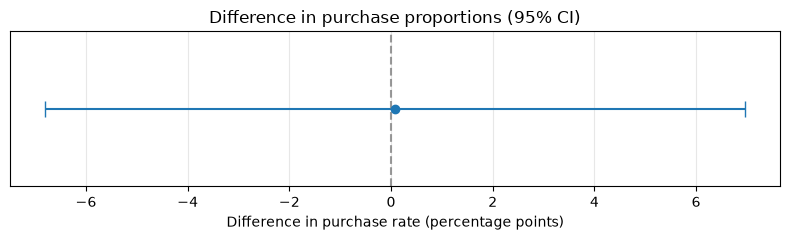

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 2.5))

plt.errorbar(
    x=difference_pp,
    y=0,
    xerr=[[
        (difference - ci_lower) * 100
    ], [
        (ci_upper - difference) * 100
    ]],
    fmt='o',
    capsize=6
)
plt.axvline(0, linestyle='--', color='gray', alpha=0.8)

plt.xlabel('Difference in purchase rate (percentage points)')
plt.yticks([])
plt.title('Difference in purchase proportions (95% CI)')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Tolkning av konfidensintervallet:
- Om intervallet inte innehåller 0 finns en statistiskt signifikant skillnad på 5-procentsnivån, med motsvarande normalapproximation.
- Om intervallet innehåller 0 kan vi inte fastställa någon statistiskt signifikant skillnad på den nivån.

Intervallet innehåller noll och både negativa och positiva värden. Det innebär att data är förenliga med att:
- Grupp B har en lägre köpandel än A.
- Grupperna har ungefär samma köpandel.
- Grupp B har en högre köpandel än A.

Vi kan inte dra slutsatsen att grupperna är likvärdiga. Vi kan bara konstatera att vi inte har kunnat påvisa någon statistiskt signifikant skillnad.

## Block B – Power och stickprovsstorlek

### Uppgift 3 – Planera ett A/B-test

Anta att köpandelen i grupp A normalt är 25 procent. Du vill planera ett tvåsidigt A/B-test med signifikansnivån 5 procent och 80 procents power.

- Beräkna hur många observationer som behövs per grupp för att kunna upptäcka en ökning från 25 till 28 procent.
- Upprepa beräkningen för en ökning från 25 till 27 procent.
- Upprepa beräkningen för en ökning från 25 till 30 procent.
- Samla resultaten i en tabell och skapa en figur som visar sambandet mellan effektstorlek och nödvändig stickprovsstorlek.
- Förklara varför mindre effekter kräver större stickprov.

**Tips:** Använd `proportion_effectsize()` och `NormalIndPower().solve_power()` från `statsmodels`. Avrunda alltid den beräknade stickprovsstorleken uppåt.

In [ ]:
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower

baseline_rate = 0.25
target_rates = [0.27, 0.28, 0.30]

alpha = 0.05
power = 0.80

solver = NormalIndPower() # skapar ett objekt av klassen NormalIndPower
results = []

for target_rate in target_rates:
    effect_size = proportion_effectsize(baseline_rate, target_rate)

    n = solver.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=power,
        ratio=1.0,
        alternative='two-sided'
    )

    results.append({
        'Group A': baseline_rate,
        'Group B': target_rate,
        'Increase (pp)': (target_rate - baseline_rate) * 100,
        'Effect size (Cohen h)': abs(effect_size),
        'n per group': int(np.ceil(n)),
        'Total n': 2 * int(np.ceil(n))
    })

results_df = pd.DataFrame(results)
results_df

,Group A,Group B,Increase (pp),Effect size (Cohen h),n per group,Total n
0,0.25,0.27,2.0,0.045604,7549,15098
1,0.25,0.28,3.0,0.068000,3395,6790
2,0.25,0.30,5.0,0.112082,1250,2500


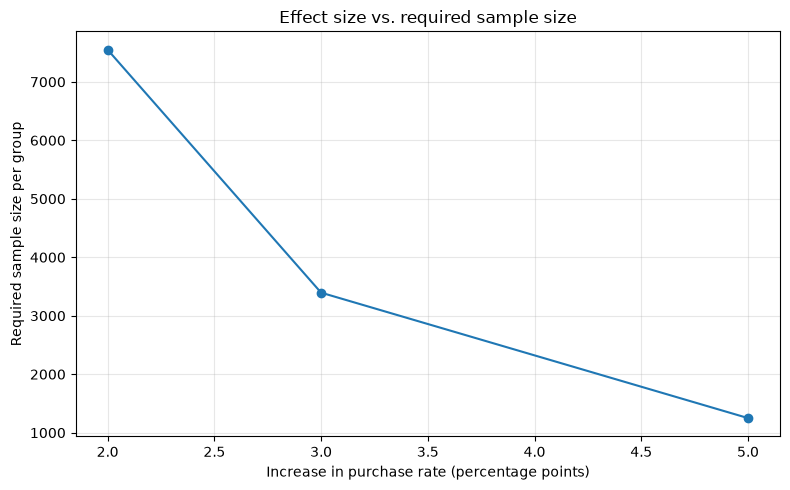

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['Increase (pp)'],
    results_df['n per group'],
    marker='o'
)

plt.xlabel('Increase in purchase rate (percentage points)')
plt.ylabel('Required sample size per group')
plt.title('Effect size vs. required sample size')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ju mindre effekt man vill kunna upptäcka, desto större stickprov behöver man, om signifikansnivå och power hålls konstanta.

## Block C – Flerfaldig testning

### Uppgift 4 – Många tester och korrigerade p-värden

Anta att följande p-värden kommer från tio analyser som genomförts samtidigt:

```python
p_values = np.array([0.001, 0.009, 0.018, 0.031, 0.047, 0.072, 0.11, 0.24, 0.51, 0.88])
```

- Avgör vilka tester som är signifikanta utan korrigering vid `alpha = 0.05`.
- Korrigera p-värdena med Bonferronimetoden.
- Korrigera dem även med Benjamini–Hochberg-metoden för FDR.
- Skapa en DataFrame med ursprungligt p-värde, korrigerat p-värde och beslut för båda metoderna.
- Jämför hur många hypoteser som förkastas med respektive metod.
- Förklara varför risken för minst ett falskt positivt resultat ökar när många tester genomförs.

**Tips:** Funktionen `statsmodels.stats.multitest.multipletests()` kan användas med metoderna `"bonferroni"` och `"fdr_bh"`.

In [ ]:
from statsmodels.stats.multitest import multipletests

p_values = np.array([0.001, 0.009, 0.018, 0.031, 0.047,
                     0.072, 0.11, 0.24, 0.51, 0.88])

alpha = 0.05
reject_original = p_values < alpha

reject_bonf, p_bonf, _, _ = multipletests(p_values, alpha=alpha, method='bonferroni')

reject_bh, p_bh, _, _ = multipletests(p_values, alpha=alpha, method='fdr_bh')

results = pd.DataFrame({'p_value': p_values,
    'significant_original': reject_original,
    'p_bonferroni': p_bonf,
    'significant_bonferroni': reject_bonf,
    'p_bh': p_bh,
    'significant_bh': reject_bh})

results

,p_value,significant_original,p_bonferroni,significant_bonferroni,p_bh,significant_bh
0,0.001,True,0.01,True,0.010000,True
1,0.009,True,0.09,False,0.045000,True
2,0.018,True,0.18,False,0.060000,False
3,0.031,True,0.31,False,0.077500,False
4,0.047,True,0.47,False,0.094000,False
5,0.072,False,0.72,False,0.120000,False
6,0.110,False,1.00,False,0.157143,False
7,0.240,False,1.00,False,0.300000,False
8,0.510,False,1.00,False,0.566667,False
9,0.880,False,1.00,False,0.880000,False


In [ ]:
print(f"Without correction: {reject_original.sum()}")
print(f"Bonferroni: {reject_bonf.sum()}")
print(f"Benjamini-Hochberg: {reject_bh.sum()}")

Without correction: 5
Bonferroni: 1
Benjamini-Hochberg: 2


Varje hypotesprövning har en viss risk att ge ett falskt positivt resultat, det vill säga att förkasta en sann nollhypotes.

Vid en signifikansnivå på 5 % är risken för ett sådant fel 5 % för varje enskilt test, förutsatt att nollhypotesen är sann.

När vi genomför flera tester ökar sannolikheten för att minst ett av dem ger ett falskt positivt resultat.